<a href="https://colab.research.google.com/github/nothd7561/linear-regression-from-scratch/blob/main/lin_reg_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn
#GOAL: to build my own linear regression from scratch
#use points (1, 2), (2, 4), (3, 5).

x_array = np.array([1,2,3])
y_array = np.array([2,4,5])

x_mean = np.mean(x_array)
y_mean = np.mean(y_array)
#puttins these two numbers together as coords, gives us the center of our data
#the best fit line passes through this point
#the best fit line is the one with the smallest total squared error, so it's the best line

x_dist_from_mean = x_array - x_mean
y_dist_from_mean = y_array - y_mean


numerator = np.sum(x_dist_from_mean * y_dist_from_mean)
denominator = np.sum(x_dist_from_mean ** 2)
slope = numerator / denominator
#used for y = mx + b to find predicted y-values

intercept = y_mean - (slope * x_mean)
#find the intercept of the line
#we know our x_mean, y_mean coord is in the line, so we could plug the points in the y=mx + b to solve for the slope

predict_array = []
for number in x_array:
  predicted_value = intercept + (number * slope)
  predict_array.append(predicted_value)
  #for every x value, calculate its predicted y value and append it to a list

miss = sum((y_array - predict_array) ** 2)
#calculated the sse of the predictions (sum of squared errors)
print(miss)
print(miss / len(y_array))
#calculate the mse (mean of squared errors)

0.16666666666666652
0.055555555555555504


In [4]:
def find_slope_intercept(x_set, y_set):
  if len(x_set) != len(y_set):
    raise ValueError('data lengths are not equal')

  x_set = np.asarray(x_set)
  y_set = np.asarray(y_set)

  x_mean = np.mean(x_set)
  y_mean = np.mean(y_set)

  x_dist_from_mean = x_set - x_mean
  y_dist_from_mean = y_set - y_mean

  numerator = np.sum(x_dist_from_mean * y_dist_from_mean)
  denominator = np.sum(x_dist_from_mean ** 2)

  if denominator == 0:
    raise ValueError('trying to divide by 0, error!')

  slope = numerator / denominator

  intercept = y_mean - (slope * x_mean)

  return slope, intercept

def predict(x_value, slope, intercept):
  x_value = np.asarray(x_value)
  predicted_value = (x_value * slope) + intercept
  return predicted_value

def find_mse(y_values, predicted_value):
  y_values = np.asarray(y_values)
  predicted_value = np.asarray(predicted_value)

  sse = np.sum((y_values - predicted_value) ** 2)
  mse = sse / len(y_values)
  return mse



In [5]:
x_list = [1,2,3]
y_list = [2,4,5]
slope1, intercept1 = find_slope_intercept(x_list, y_list)
prediction = predict(x_list, slope1, intercept1)
mse = find_mse(y_list, prediction)
print(mse)

0.055555555555555504


In [6]:
x_list = [1,2,3]
y_list = [1,2,3,4]
#slope, intercept = find_slope_intercept(x_list, y_list)
#prediction = predict(x_list, slope, intercept)
#mse = find_mse(y_list, prediction)
#print(mse)
#testing the stop function if

In [7]:
x_list = [2,2,2]
y_list = [2,4,5]
#slope, intercept = find_slope_intercept(x_list, y_list)
#prediction = predict(x_list, slope, intercept)
#mse = find_mse(y_list, prediction)
#print(mse)
#testing the other error

In [8]:
rng = np.random.default_rng(42)
#create a seed so that we get same random data

x = np.arange(100)
#generate x values from 1-100, put it in an array
#the actual x values

noise = rng.normal(loc=0, scale=2, size=100)
#generate noise values, so points don't sit exactly on the line

y = 3 * x + 5 + noise
#have a relationship to generate the atual y points
#make a base line to generate random pairs of points, add noise to have variation, like realistic data

slope, intercept = find_slope_intercept(x, y)
prediction = predict(x, slope, intercept)
mse = find_mse(y, prediction)
#print(slope, intercept)
#print(prediction)
#print(mse)


In [9]:
from sklearn.linear_model import LinearRegression
#cross checking random data with sklearn
x_sklearn = x.reshape(-1,1)
#turn the array into 1 column, 100 rows since sklearn reads tables. it can read 2D arrays

lin_reg = LinearRegression()
#create the model for linear regression

lin_reg = lin_reg.fit(x_sklearn, y)
#find the best fitting line through the points
#stores the slope and intercept of that best fitting line in fit_it

intercept_sklearn = lin_reg.intercept_


slope_sklearn = lin_reg.coef_[0]
predict_it = lin_reg.predict(x_sklearn)
#use the x values to predict y values

my_pair = slope, intercept
sklearn_pair = slope_sklearn, intercept_sklearn
print(np.isclose(my_pair, sklearn_pair))
print(my_pair, sklearn_pair)
print(predict_it)


[ True  True]
(np.float64(2.991524679453793), np.float64(5.318989144069576)) (np.float64(2.9915246794537937), np.float64(5.318989144069519))
[  5.31898914   8.31051382  11.3020385   14.29356318  17.28508786
  20.27661254  23.26813722  26.2596619   29.25118658  32.24271126
  35.23423594  38.22576062  41.2172853   44.20880998  47.20033466
  50.19185934  53.18338402  56.17490869  59.16643337  62.15795805
  65.14948273  68.14100741  71.13253209  74.12405677  77.11558145
  80.10710613  83.09863081  86.09015549  89.08168017  92.07320485
  95.06472953  98.05625421 101.04777889 104.03930357 107.03082825
 110.02235292 113.0138776  116.00540228 118.99692696 121.98845164
 124.97997632 127.971501   130.96302568 133.95455036 136.94607504
 139.93759972 142.9291244  145.92064908 148.91217376 151.90369844
 154.89522312 157.8867478  160.87827248 163.86979716 166.86132183
 169.85284651 172.84437119 175.83589587 178.82742055 181.81894523
 184.81046991 187.80199459 190.79351927 193.78504395 196.77656863
 

In [10]:
x_sklearn1 = x_array.reshape(-1,1)
#cross checking small data set with sklearn

fit_it1 = lin_reg.fit(x_sklearn1, y_array)


intercept_sklearn1 = fit_it1.intercept_
slope_sklearn1 = fit_it1.coef_[0]

my_pair1 = slope1, intercept1
sklearn_pair1 = slope_sklearn1, intercept_sklearn1
print(np.isclose(my_pair1, sklearn_pair1))
print(my_pair1, sklearn_pair1)

[ True  True]
(np.float64(1.5), np.float64(0.6666666666666665)) (np.float64(1.4999999999999998), np.float64(0.666666666666667))


In [11]:
import seaborn as sns

tips_df = sns.load_dataset('tips')


total_bill = tips_df['total_bill'].to_numpy() #x values
tips = tips_df['tip'].to_numpy() #y values

sl, inter = find_slope_intercept(total_bill, tips)
predictions_base = predict(total_bill, sl, inter)
mse_base = find_mse(tips, predictions_base)
#print(sl, inter, predictions_base)

reshaped = total_bill.reshape(-1,1)

lin_regs = LinearRegression()

lin_regs = lin_regs.fit(reshaped, tips)
lin_coeff = lin_regs.coef_[0]
lin_int = lin_regs.intercept_

predict_shi = lin_regs.predict(reshaped)
print(lin_coeff, lin_int)
sklearn_pair = lin_coeff, lin_int
my_pairs = sl, inter
print(np.isclose(sklearn_pair, my_pairs), np.allclose(predictions_base, predict_shi))


0.10502451738435337 0.9202696135546731
[ True  True] True


(np.float64(1.5000000000000677), np.float64(0.6666666666665123))


<Axes: >

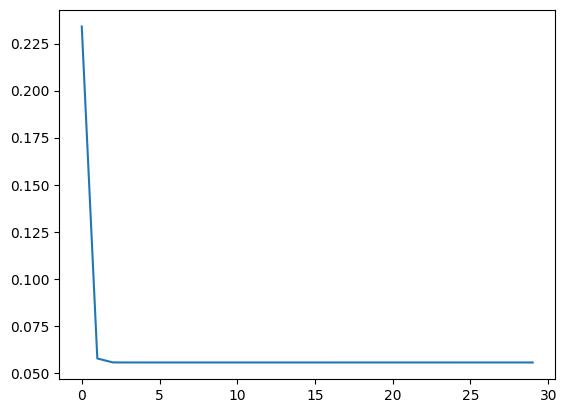

In [21]:

slope3 = 0
inter3 = 0
learning_rate = 0.1
iterations = 1000

mse_history = []
iteration_history = []

for i in range(iterations):
  predicted2 = predict(x_array, slope3, inter3)
  misses = y_array - predicted2

  slope_gradient = -2 * np.mean(x_array * misses)
  intercept_gradient = -2 * np.mean(misses)


  slope3 -= learning_rate * slope_gradient
  inter3 -= learning_rate * intercept_gradient

  grad_predict = predict(x_array, slope3, inter3)
  mse3 = find_mse(y_array, grad_predict)
  mse_history.append(mse3)

  grad_results = slope3, inter3

  iteration_history.append(grad_results)
  #at 2 iterations, we got -1.666, -.7333 and -5.182 and -2.28
print(iteration_history[-1])
sns.lineplot(x=range(len(mse_history[:30])), y=mse_history[:30])




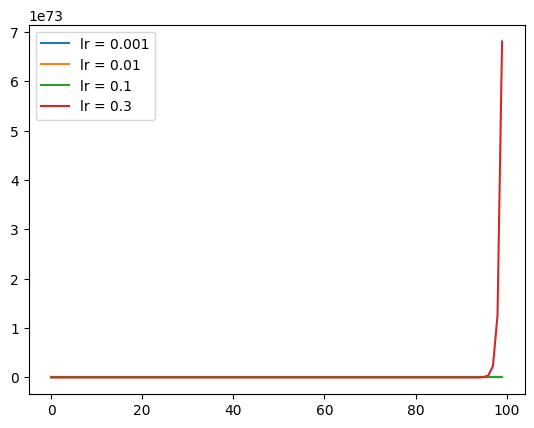

In [23]:
def gradient_descent(x, y, learning_rate, iterations):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    slope, intercept = 0.0, 0.0
    mse_history = []

    for _ in range(iterations):
        predicted = intercept + slope * x
        misses = y - predicted
        mse_history.append(np.mean(misses ** 2))

        slope_gradient = -2 * np.mean(x * misses)
        intercept_gradient = -2 * np.mean(misses)

        slope -= learning_rate * slope_gradient
        intercept -= learning_rate * intercept_gradient

    return slope, intercept, mse_history

rates = [0.001, 0.01, 0.1, 0.3]

for rate in rates:
  slopp, interr, historyy = gradient_descent(x_array, y_array, rate, 100)
  ax = sns.lineplot(x=range(len(historyy)), y=historyy, label=f"lr = {rate}")


In [ ]:
test1 = gradient_descent(x_array, y_array,)